In [ ]:
!pip install ucimlrepo -q

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

pd.set_option('display.max_columns', None)
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

In [ ]:
# dataset
heart = fetch_ucirepo(id=45)

X = heart.data.features
y = heart.data.targets

df_raw = pd.concat([X, y], axis=1)

print(f"size : {df_raw.shape[0]}  row × {df_raw.shape[1]} column ")
print(f" column: {df_raw.columns.tolist()}")

size : 303  row × 14 column 
 column: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'num']


In [ ]:
df_raw.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63,1,1,145,233,1,2,150,0,2.3,3,0.0,6.0,0
1,67,1,4,160,286,0,2,108,1,1.5,2,3.0,3.0,2
2,67,1,4,120,229,0,2,129,1,2.6,2,2.0,7.0,1
3,37,1,3,130,250,0,0,187,0,3.5,3,0.0,3.0,0
4,41,0,2,130,204,0,2,172,0,1.4,1,0.0,3.0,0


In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(3), int64(11)
memory usage: 33.3 KB


In [ ]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,303.0,54.438944,9.038662,29.0,48.0,56.0,61.0,77.0
sex,303.0,0.679868,0.467299,0.0,0.0,1.0,1.0,1.0
cp,303.0,3.158416,0.960126,1.0,3.0,3.0,4.0,4.0
trestbps,303.0,131.689769,17.599748,94.0,120.0,130.0,140.0,200.0
chol,303.0,246.693069,51.776918,126.0,211.0,241.0,275.0,564.0
fbs,303.0,0.148515,0.356198,0.0,0.0,0.0,0.0,1.0
restecg,303.0,0.990099,0.994971,0.0,0.0,1.0,2.0,2.0
thalach,303.0,149.607261,22.875003,71.0,133.5,153.0,166.0,202.0
exang,303.0,0.326733,0.469794,0.0,0.0,0.0,1.0,1.0
oldpeak,303.0,1.039604,1.161075,0.0,0.0,0.8,1.6,6.2


In [ ]:
missing = df_raw.isnull().sum()
missing_pct = (missing / len(df_raw) * 100).round(2)

missing_df = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct
}).sort_values('Missing Count', ascending=False)

print(" missing values:")
print(missing_df[missing_df['Missing Count'] > 0])

 missing values:
      Missing Count  Missing %
ca                4       1.32
thal              2       0.66


In [ ]:
# column description
columns_description = pd.DataFrame({
    'Column': df_raw.columns,
    'Description': [
        'Age in years',
        'Sex (1 = male; 0 = female)',
        'Chest pain type (1-4)',
        'Resting blood pressure (mm Hg)',
        'Serum cholesterol (mg/dl)',
        'Fasting blood sugar > 120 mg/dl (1 = true; 0 = false)',
        'Resting ECG results (0-2)',
        'Max heart rate achieved',
        'Exercise induced angina (1 = yes; 0 = no)',
        'ST depression induced by exercise',
        'Slope of peak exercise ST segment (1-3)',
        'Number of major vessels colored by fluoroscopy (0-3)',
        'Thalassemia (3 = normal; 6 = fixed defect; 7 = reversible defect)',
        'Diagnosis of heart disease (0 = no disease; 1-4 = disease severity)'
    ]
})
columns_description

,Column,Description
0,age,Age in years
1,sex,Sex (1 = male; 0 = female)
2,cp,Chest pain type (1-4)
3,trestbps,Resting blood pressure (mm Hg)
4,chol,Serum cholesterol (mg/dl)
5,fbs,Fasting blood sugar > 120 mg/dl (1 = true; 0 =...
6,restecg,Resting ECG results (0-2)
7,thalach,Max heart rate achieved
8,exang,Exercise induced angina (1 = yes; 0 = no)
9,oldpeak,ST depression induced by exercise


In [ ]:
#raw
df_raw.to_csv('heart_disease_raw.csv', index=False)
print(" data/heart_disease_raw.csv")

 data/heart_disease_raw.csv


In [ ]:
df = df_raw.copy()

print("Missing values in each column:")
print(df.isnull().sum())

print("Question marks in each column:")
print((df.astype(str) == '?').sum())

Missing values in each column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num         0
dtype: int64
Question marks in each column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64


In [ ]:
for col in ['ca', 'thal']:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
num         0
dtype: int64


In [ ]:
print("Data types:")
print(df.dtypes)

Data types:
age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca          float64
thal        float64
num           int64
dtype: object


In [ ]:
df[['ca', 'thal']] = df[['ca', 'thal']].astype(int)

print(df[['ca', 'thal']].dtypes)

ca      int64
thal    int64
dtype: object


In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


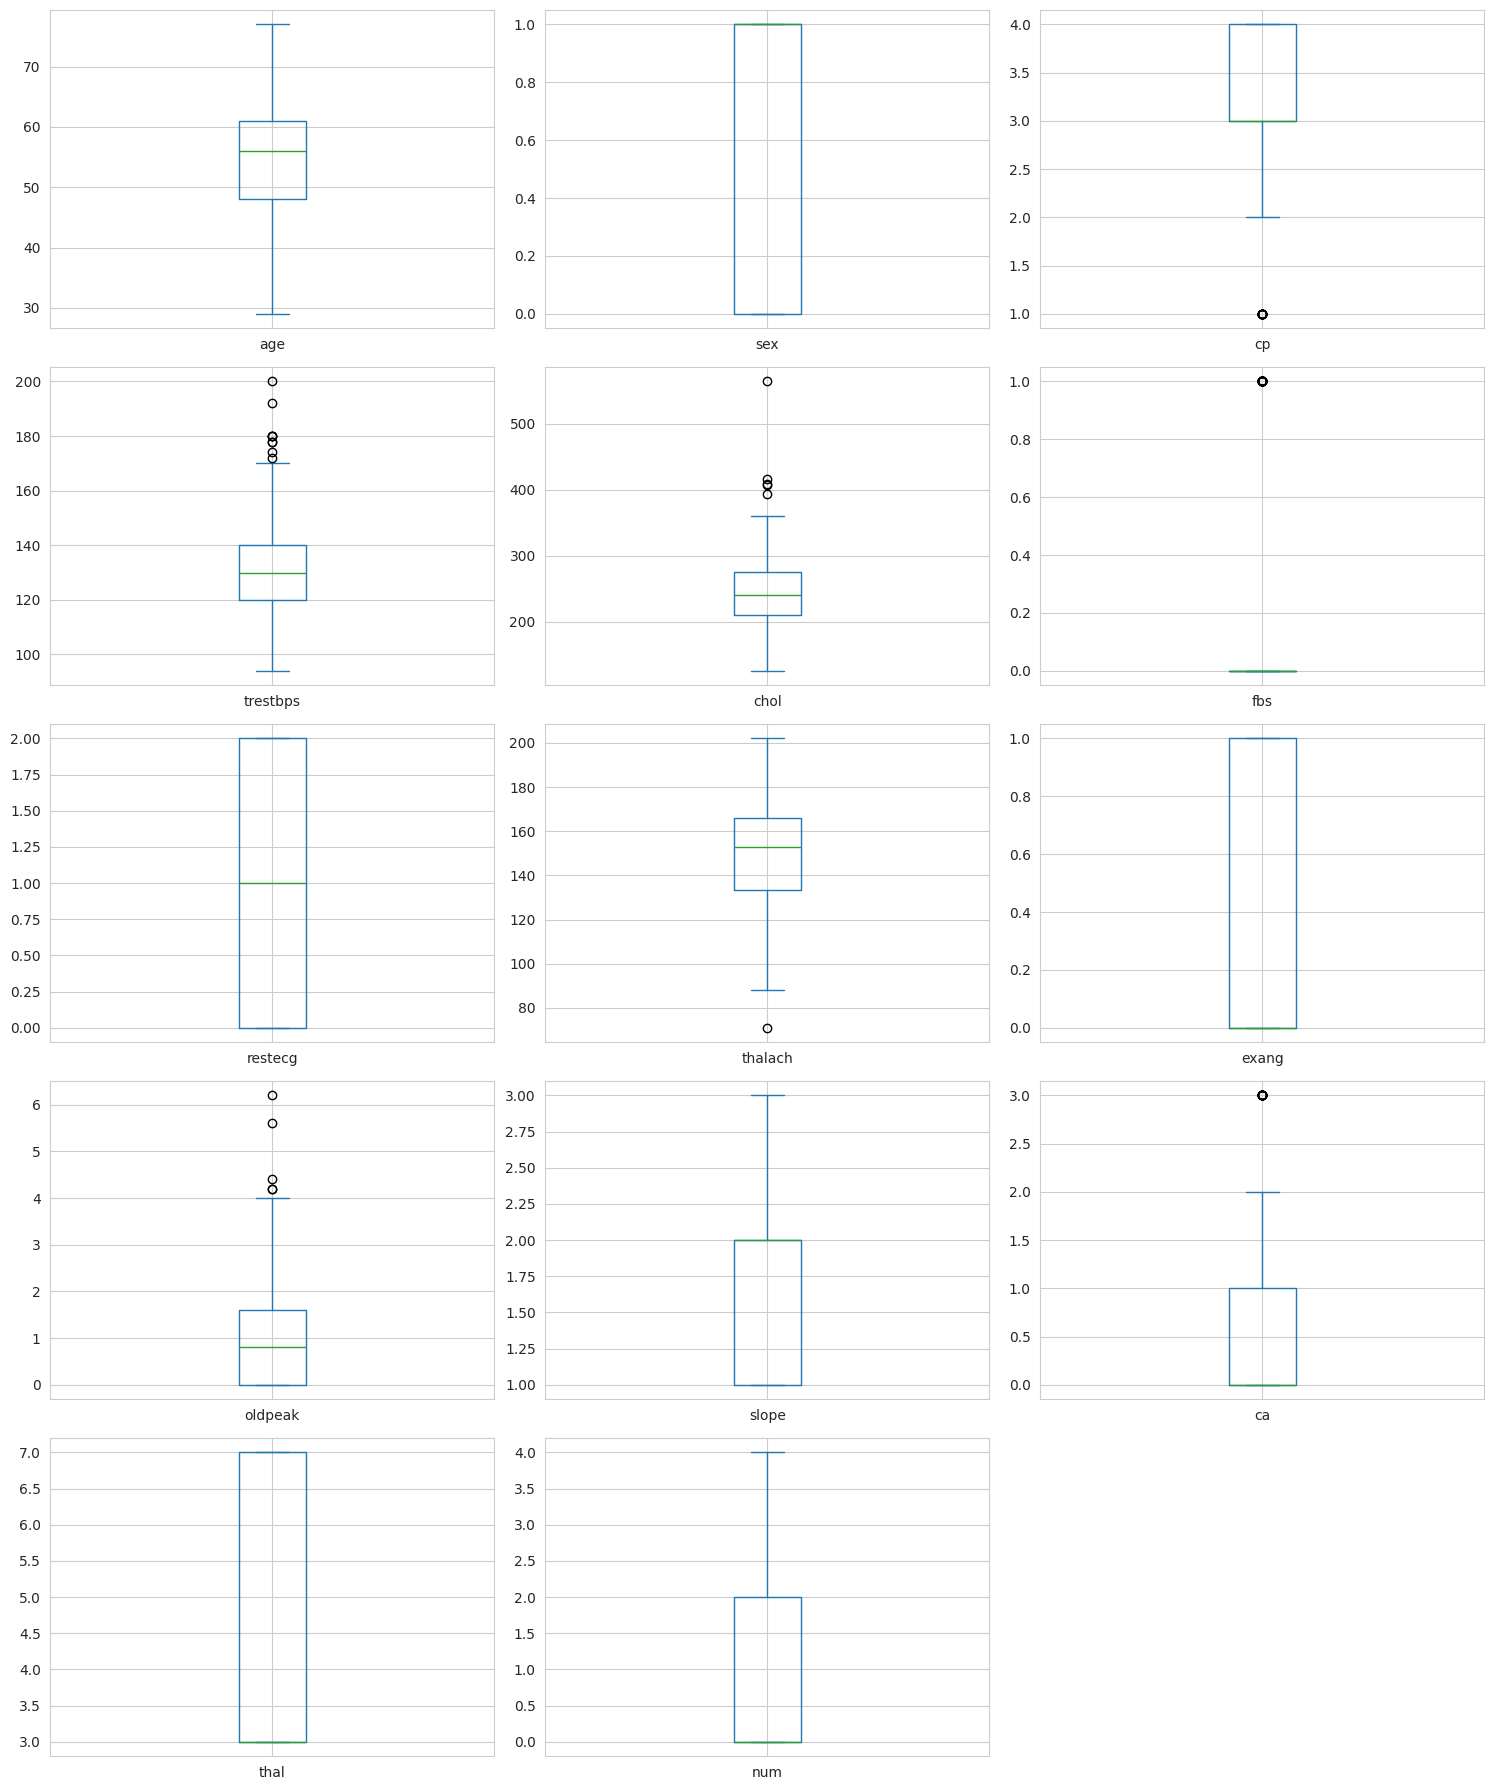

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns

df[numeric_cols].plot(
    kind='box',
    subplots=True,
    layout=(5, 3),
    figsize=(15, 18),
    sharex=False,
    sharey=False
)

plt.tight_layout()
plt.show()

In [ ]:
df.to_csv('heart_disease_clean.csv', index=False)

print("Cleaned dataset saved successfully!")
print("Dataset shape:", df.shape)

Cleaned dataset saved successfully!
Dataset shape: (303, 14)


In [ ]:
X = df.drop(columns=['num'])
y = df['num']

X_encoded = pd.get_dummies(
    X,
    columns=['cp', 'restecg', 'thal'],
    dtype=int
)

print("Original features shape:", X.shape)
print("Encoded features shape:", X_encoded.shape)
print("Target shape:", y.shape)

Original features shape: (303, 13)
Encoded features shape: (303, 20)
Target shape: (303,)


In [ ]:
print("Encoded columns:")
print(X_encoded.columns.tolist())

print("\nMissing values in encoded features:")
print(X_encoded.isnull().sum().sum())

print("\nMissing values in target:")
print(y.isnull().sum())

Encoded columns:
['age', 'sex', 'trestbps', 'chol', 'fbs', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'cp_1', 'cp_2', 'cp_3', 'cp_4', 'restecg_0', 'restecg_1', 'restecg_2', 'thal_3', 'thal_6', 'thal_7']

Missing values in encoded features:
0

Missing values in target:
0


In [ ]:
# Reload the cleaned dataset to work from a known state
df_model = pd.read_csv('heart_disease_clean.csv')

# Convert multi-class target (0-4) to binary (0 = healthy, 1 = diseased)
df_model['target_clf'] = (df_model['num'] > 0).astype(int)

print(f"Dataset shape: {df_model.shape}")
print("\nBinary target distribution:")
print(df_model['target_clf'].value_counts())
print(f"\nDisease ratio: {df_model['target_clf'].mean()*100:.1f}%")

Dataset shape: (303, 15)

Binary target distribution:
target_clf
0    164
1    139
Name: count, dtype: int64

Disease ratio: 45.9%


In [ ]:
# Regression target decision: 'age'
# Rationale: age is a natural continuous variable.
# Goal: predict patient age from clinical features (NOT disease diagnosis).
# Note: 'age' is excluded from regression features to avoid data leakage.

print("Regression Target = age")
print(f"Range: {df_model['age'].min()} - {df_model['age'].max()}")
print(f"Mean: {df_model['age'].mean():.1f}")
print(f"Std:  {df_model['age'].std():.1f}")

Regression Target = age
Range: 29 - 77
Mean: 54.4
Std:  9.0


/tmp/ipykernel_1733/501822158.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='target_clf', data=df_model, palette='Set2', ax=axes[0])


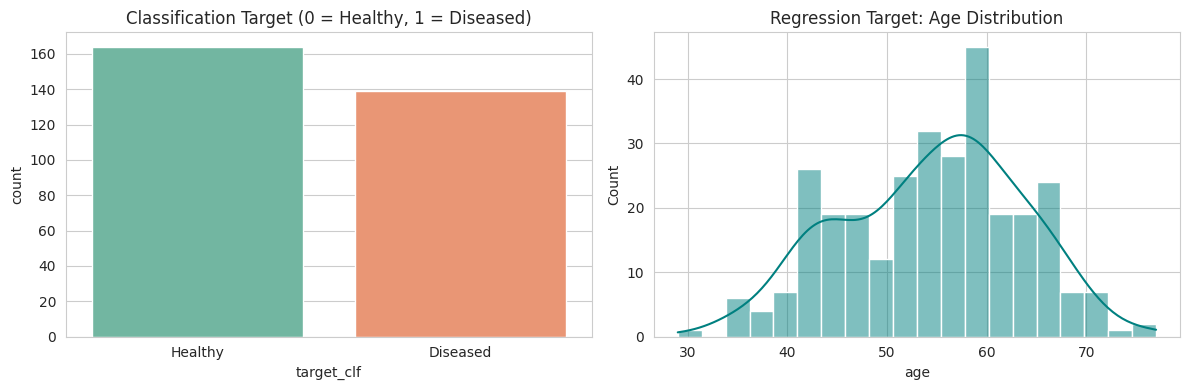

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Classification target distribution
sns.countplot(x='target_clf', data=df_model, palette='Set2', ax=axes[0])
axes[0].set_title('Classification Target (0 = Healthy, 1 = Diseased)')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Healthy', 'Diseased'])

# Regression target distribution
sns.histplot(df_model['age'], kde=True, bins=20, color='teal', ax=axes[1])
axes[1].set_title('Regression Target: Age Distribution')

plt.tight_layout()
plt.savefig('eda_targets.png', dpi=150, bbox_inches='tight')
plt.show()

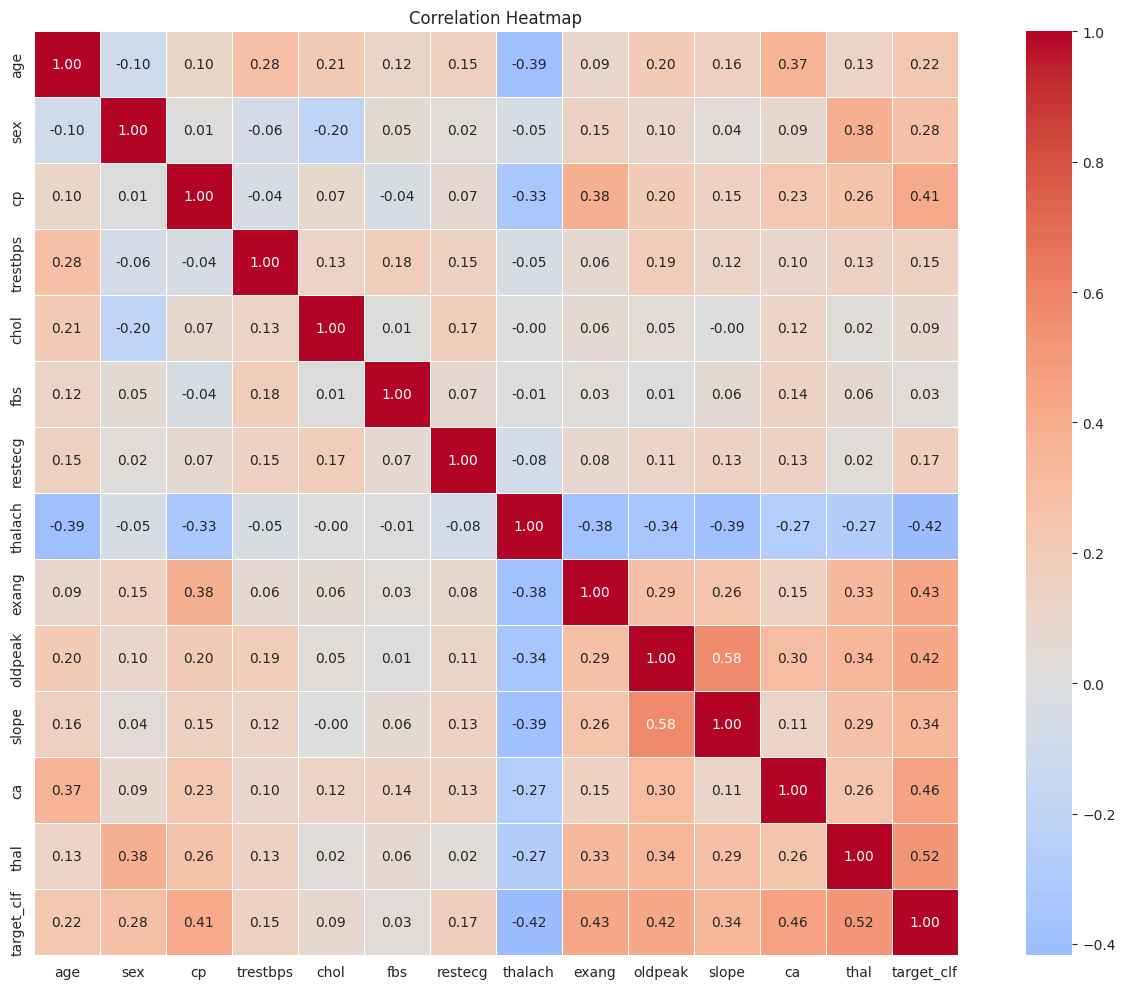

In [ ]:
plt.figure(figsize=(14, 10))
corr = df_model.drop(columns=['num']).corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.savefig('correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

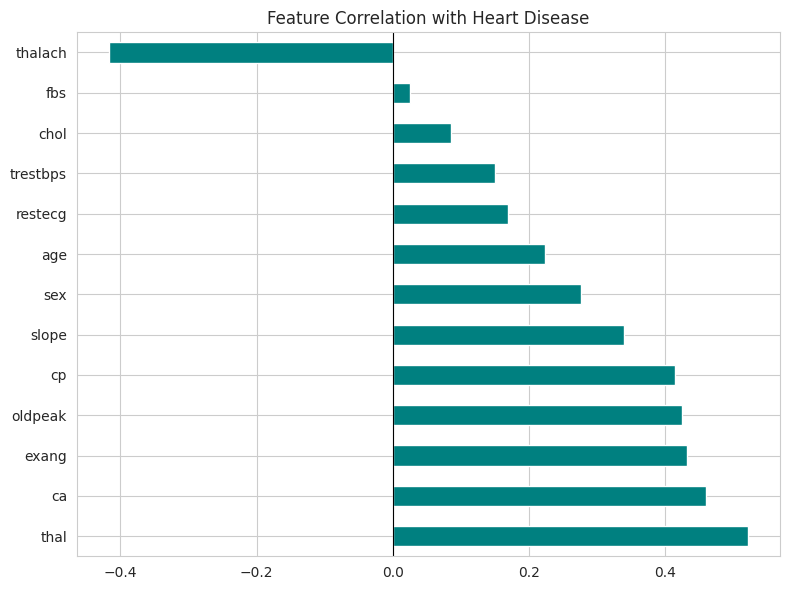

thal        0.522057
ca          0.460033
exang       0.431894
oldpeak     0.424510
cp          0.414446
slope       0.339213
sex         0.276816
age         0.223120
restecg     0.169202
trestbps    0.150825
chol        0.085164
fbs         0.025264
thalach    -0.417167
dtype: float64


In [ ]:
target_corr = df_model.drop(columns=['num', 'target_clf']).corrwith(
    df_model['target_clf']).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
target_corr.plot(kind='barh', color='teal')
plt.title('Feature Correlation with Heart Disease')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig('features_vs_target.png', dpi=150, bbox_inches='tight')
plt.show()

print(target_corr)

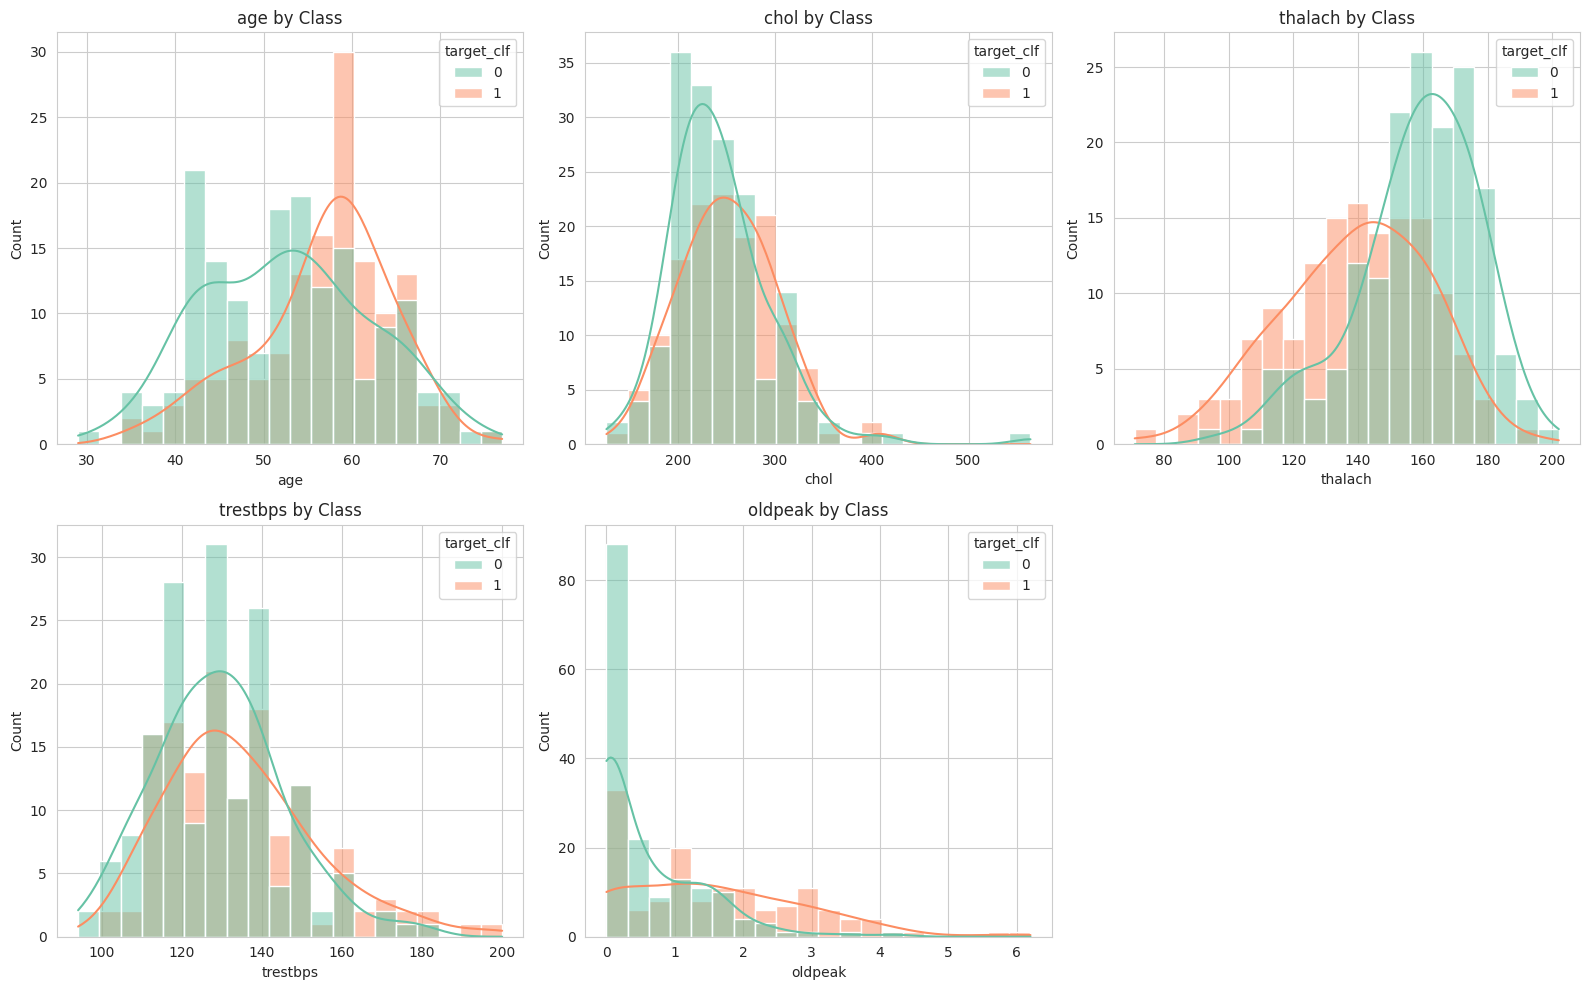

In [ ]:
important_cols = ['age', 'chol', 'thalach', 'trestbps', 'oldpeak']

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(important_cols):
    sns.histplot(data=df_model, x=col, hue='target_clf', kde=True,
                 palette='Set2', ax=axes[i], bins=20)
    axes[i].set_title(f'{col} by Class')

axes[-1].axis('off')
plt.tight_layout()
plt.savefig('features_distribution_by_class.png', dpi=150, bbox_inches='tight')
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Classification features: everything except 'num' and 'target_clf'
X_clf = df_model.drop(columns=['num', 'target_clf'])
y_clf = df_model['target_clf']

# 80/20 split with stratification to preserve class balance
X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(
    X_clf, y_clf,
    test_size=0.2,
    random_state=42,
    stratify=y_clf
)

print(f"Train shape: {X_train_clf.shape}")
print(f"Test shape:  {X_test_clf.shape}")
print(f"\nTrain class balance: {y_train_clf.value_counts().to_dict()}")
print(f"Test class balance:  {y_test_clf.value_counts().to_dict()}")

Train shape: (242, 13)
Test shape:  (61, 13)

Train class balance: {0: 131, 1: 111}
Test class balance:  {0: 33, 1: 28}


In [ ]:
# Regression features: exclude target ('age'), and both label columns
X_reg = df_model.drop(columns=['num', 'target_clf', 'age'])
y_reg = df_model['age']

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg,
    test_size=0.2,
    random_state=42
)

print(f"Regression train shape: {X_train_reg.shape}")
print(f"Regression test shape:  {X_test_reg.shape}")

Regression train shape: (242, 12)
Regression test shape:  (61, 12)


In [ ]:
from sklearn.preprocessing import StandardScaler

# Scale features (required for distance-based and linear models)
scaler_clf = StandardScaler()
X_train_clf_scaled = scaler_clf.fit_transform(X_train_clf)
X_test_clf_scaled = scaler_clf.transform(X_test_clf)

scaler_reg = StandardScaler()
X_train_reg_scaled = scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled = scaler_reg.transform(X_test_reg)

print("Scaling done.")
print(f"Sample before scaling (first 3 values): {X_train_clf.iloc[0, :3].values}")
print(f"Sample after scaling  (first 3 values): {X_train_clf_scaled[0, :3].round(2)}")

Scaling done.
Sample before scaling (first 3 values): [48.  1.  4.]
Sample after scaling  (first 3 values): [-0.73  0.68  0.87]


In [ ]:
# Save classification files (scaled) for teammate
pd.DataFrame(X_train_clf_scaled, columns=X_train_clf.columns).to_csv('X_train_clf_scaled.csv', index=False)
pd.DataFrame(X_test_clf_scaled, columns=X_test_clf.columns).to_csv('X_test_clf_scaled.csv', index=False)
y_train_clf.to_csv('y_train_clf.csv', index=False)
y_test_clf.to_csv('y_test_clf.csv', index=False)

# Save regression files (scaled)
pd.DataFrame(X_train_reg_scaled, columns=X_train_reg.columns).to_csv('X_train_reg_scaled.csv', index=False)
pd.DataFrame(X_test_reg_scaled, columns=X_test_reg.columns).to_csv('X_test_reg_scaled.csv', index=False)
y_train_reg.to_csv('y_train_reg.csv', index=False)
y_test_reg.to_csv('y_test_reg.csv', index=False)

print("All split and scaled files saved.")

All split and scaled files saved.
